# 2014 — Neural Turing Machines: Networks with External Memory

**Paper:** Alex Graves, Greg Wayne & Ivo Danihelka, *"Neural Turing Machines"* (arXiv 2014). Successor: the Differentiable Neural Computer (Graves et al., Nature 2016). In parallel: Memory Networks (Weston, Chopra & Bordes, 2014) and End-to-End Memory Networks (Sukhbaatar et al., 2015).

An LSTM (notebook 13) stores everything in a fixed-size hidden vector, and the same weights must both compute and remember. The NTM separates the two: a neural **controller** reads from and writes to an external **memory matrix** $M\in\mathbb R^{N\times W}$ through **differentiable attention**, so the whole machine trains with backpropagation.

Each head produces a weighting $w_t$ over the $N$ memory rows in four steps:
1. **Content addressing:** $w^c_t \propto \exp\big(\beta_t \cos(k_t, M_t[i])\big)$ (find rows similar to a key)
2. **Interpolation:** $w^g_t = g_t w^c_t + (1-g_t) w_{t-1}$ (or stay near the previous location)
3. **Shift:** circularly convolve with a small learned shift distribution $s_t$ (move by −1, 0, +1)
4. **Sharpen:** $w_t \propto (\tilde w_t)^{\gamma_t}$

Reading is $r_t = \sum_i w_t(i) M_t[i]$; writing is an **erase** then an **add**: $M_t = M_{t-1}\odot(1 - w_t e_t^\top) + w_t a_t^\top$.

Content addressing is the same soft key–value lookup as Bahdanau attention (notebook 24) and, three years later, the Transformer (notebook 37).

**Task (from the paper): copy.** Read a sequence of random 8-bit vectors, then reproduce it. Train on lengths 1–10 and test on longer ones. An algorithm ("write each item to the next row, then read them back in order") generalises to any length; a memorised mapping does not.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
device = torch.device("cpu")      # small, sequential computation: CPU is fast enough and avoids per-step GPU overhead
torch.set_num_threads(4)

PyTorch 2.15.0 | device: mps


In [2]:
BITS = 8
def copy_batch(B, T):
    """Input: T random vectors, then a delimiter flag; target: the same T vectors, during the T steps after the delimiter."""
    seq = (torch.rand(B, T, BITS) < 0.5).float()
    x = torch.zeros(B, 2 * T + 1, BITS + 1)
    x[:, :T, :BITS] = seq; x[:, T, BITS] = 1.0
    return x, seq

class NTM(nn.Module):
    def __init__(self, N=64, W=20, hidden=100, shifts=3):
        super().__init__()
        self.N, self.W, self.S = N, W, shifts
        self.ctrl = nn.LSTMCell(BITS + 1 + W, hidden)
        n_addr = W + 1 + 1 + shifts + 1                                       # key, beta, gate, shift, gamma
        self.read_head, self.write_head = nn.Linear(hidden, n_addr), nn.Linear(hidden, n_addr + 2 * W)
        self.out = nn.Linear(hidden + W, BITS)
        # Initial memory: small fixed random values. If every row started identical, content addressing could not tell rows
        # apart and shifting a uniform weighting would leave it uniform, so the heads could never learn to step through memory.
        self.register_buffer("M0", torch.empty(N, W).uniform_(-1, 1) / math.sqrt(N + W))
        self.r0 = nn.Parameter(torch.randn(W) * 0.01)
        self.register_buffer("w0", F.one_hot(torch.tensor(0), N).float())   # both heads start focused on row 0
        self.h0, self.c0 = nn.Parameter(torch.zeros(hidden)), nn.Parameter(torch.zeros(hidden))

    def address(self, p, M, w_prev):
        W, S = self.W, self.S
        k, beta, g = p[:, :W], F.softplus(p[:, W]), torch.sigmoid(p[:, W + 1])
        s, gamma = F.softmax(p[:, W + 2:W + 2 + S], -1), 1 + F.softplus(p[:, W + 2 + S])
        wc = F.softmax(beta[:, None] * F.cosine_similarity(M, k[:, None], dim=-1, eps=1e-8), -1)   # 1. content
        wg = g[:, None] * wc + (1 - g[:, None]) * w_prev                                          # 2. interpolate
        ws = sum(s[:, j:j + 1] * torch.roll(wg, j - S // 2, dims=1) for j in range(S))            # 3. circular shift
        w = ws.clamp_min(1e-12) ** gamma[:, None]                                                 # 4. sharpen
        return w / w.sum(-1, keepdim=True)

    def forward(self, x, return_weights=False):
        B, T, _ = x.shape
        M = self.M0.expand(B, -1, -1).clone()
        r, wr = self.r0.expand(B, -1), self.w0.expand(B, -1)
        ww, h, c = wr, self.h0.expand(B, -1), self.c0.expand(B, -1)
        outs, Wr, Ww = [], [], []
        for t in range(T):
            h, c = self.ctrl(torch.cat([x[:, t], r], -1), (h, c))
            pw = self.write_head(h)
            ww = self.address(pw[:, :-2 * self.W], M, ww)
            e, a = torch.sigmoid(pw[:, -2 * self.W:-self.W]), torch.tanh(pw[:, -self.W:])
            M = M * (1 - ww[:, :, None] * e[:, None]) + ww[:, :, None] * a[:, None]                 # erase, then add
            wr = self.address(self.read_head(h), M, wr)
            r = (wr[:, :, None] * M).sum(1)                                                       # read
            outs.append(self.out(torch.cat([h, r], -1))); Wr.append(wr); Ww.append(ww)
        y = torch.stack(outs, 1)
        return (y, torch.stack(Wr, 1), torch.stack(Ww, 1)) if return_weights else y

class LSTMBaseline(nn.Module):
    def __init__(self, hidden=256):
        super().__init__(); self.lstm = nn.LSTM(BITS + 1, hidden, num_layers=2, batch_first=True); self.out = nn.Linear(hidden, BITS)
    def forward(self, x): return self.out(self.lstm(x)[0])

def loss_and_errors(model, x, seq):
    T = seq.shape[1]
    logits = model(x)[:, T + 1:]
    loss = F.binary_cross_entropy_with_logits(logits, seq)
    bit_err = ((logits > 0).float() != seq).float().sum((1, 2)).mean().item()          # wrong bits per sequence
    return loss, bit_err

def train(model, steps, B=16, max_len=10, lr=3e-4, seed=0):
    seed_everything(seed); opt = torch.optim.Adam(model.parameters(), lr=lr); curve = []
    for s in range(steps):
        x, seq = copy_batch(B, random.randint(1, max_len))
        loss, err = loss_and_errors(model, x, seq)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 10); opt.step()
        curve.append(loss.item())
    return curve

NTM  trained in 183s, 62,880 params


LSTM trained in 88s, 801,800 params


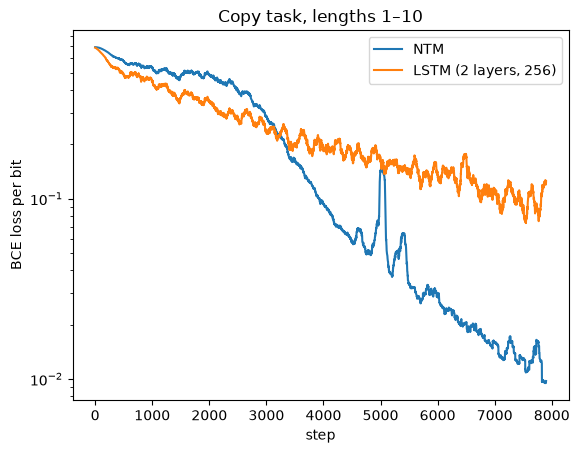

In [3]:
seed_everything(0); t0 = time.time(); ntm = NTM(); ntm_curve = train(ntm, 8000)
print(f"NTM  trained in {time.time() - t0:.0f}s, {sum(p.numel() for p in ntm.parameters()):,} params")
seed_everything(0); t0 = time.time(); lstm = LSTMBaseline(); lstm_curve = train(lstm, 8000)
print(f"LSTM trained in {time.time() - t0:.0f}s, {sum(p.numel() for p in lstm.parameters()):,} params")
smooth = lambda c: np.convolve(c, np.ones(100) / 100, mode="valid")
plt.plot(smooth(ntm_curve), label="NTM"); plt.plot(smooth(lstm_curve), label="LSTM (2 layers, 256)")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("BCE loss per bit"); plt.title("Copy task, lengths 1–10"); plt.legend(); plt.show()

## Generalising to longer sequences
Both models only ever saw lengths up to 10. Errors are in wrong bits per sequence (out of $8T$).

In [4]:
torch.manual_seed(123)
with torch.no_grad():
    for T in [5, 10, 15, 20, 30, 40]:
        x, seq = copy_batch(64, T)
        e_ntm, e_lstm = loss_and_errors(ntm, x, seq)[1], loss_and_errors(lstm, x, seq)[1]
        print(f"length {T:2d}: NTM {e_ntm:6.2f} wrong bits   LSTM {e_lstm:6.2f} wrong bits   (of {8 * T})")

length  5: NTM   0.00 wrong bits   LSTM   0.12 wrong bits   (of 40)
length 10: NTM   0.00 wrong bits   LSTM  10.53 wrong bits   (of 80)
length 15: NTM   0.02 wrong bits   LSTM  39.47 wrong bits   (of 120)
length 20: NTM   1.34 wrong bits   LSTM  70.34 wrong bits   (of 160)


length 30: NTM   0.19 wrong bits   LSTM 113.25 wrong bits   (of 240)
length 40: NTM   2.06 wrong bits   LSTM 153.17 wrong bits   (of 320)


## What did the NTM learn? Look at its memory accesses
For one sequence of length 20: which memory row the write head uses at each input step, and which row the read head uses at each output step. A learned algorithm shows up as two diagonal lines: write rows in order, then read them back in the same order.

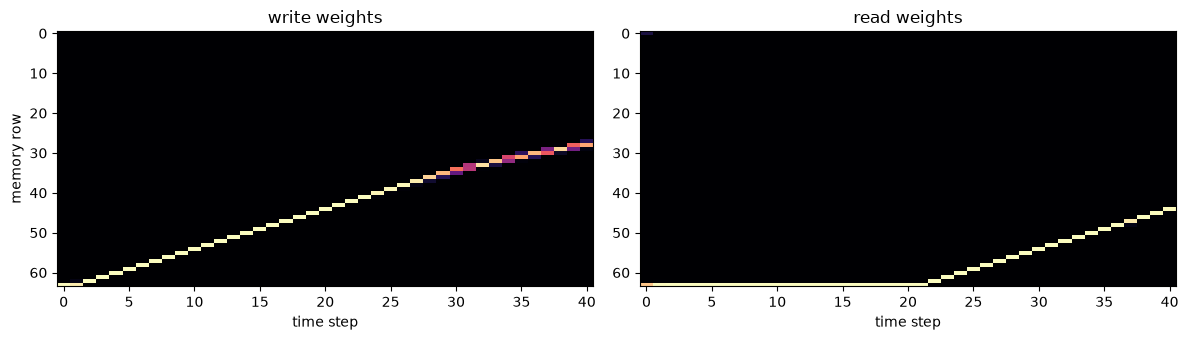

In [5]:
with torch.no_grad():
    x, seq = copy_batch(1, 20)
    y, Wr, Ww = ntm(x, return_weights=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].imshow(Ww[0].T, aspect="auto", cmap="magma"); axes[0].set(title="write weights", xlabel="time step", ylabel="memory row")
axes[1].imshow(Wr[0].T, aspect="auto", cmap="magma"); axes[1].set(title="read weights", xlabel="time step")
plt.tight_layout(); plt.show()

## Takeaways
- **Separate compute from storage.** A controller with a small state can manipulate a large memory, and because addressing is soft (attention), the whole system is differentiable.
- The NTM learns a **copy algorithm** (sequential write, then sequential read with the shift mechanism), which generalises past the training lengths; the LSTM learns a mapping that breaks beyond them. How far the NTM generalises depends on the run, and NTMs were notoriously finicky to train, which limited their adoption.
- **Legacy:** content-based addressing became attention in the Transformer, which "writes" every token to its KV cache and reads with soft keys. Explicit memory layers returned in 2025–26 as conditional memory (Engram, notebook 77) and delta-rule linear attention (notebook 70), whose state update is literally an erase-then-add write.